# 28 LLM Lokal untuk Ekstraksi Terstruktur

Memakai LLM kecil yang jalan offline untuk mengubah teks menjadi data terstruktur. Contoh: sentimen SmSA untuk audit,
lalu ekstraksi aspek dari komentar MBG.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Ekstraksi terstruktur dengan LLM kecil lokal |
| **Unit prediksi** | Satu komentar mendapat JSON berisi sentimen dan aspek |
| **Metrik** | Macro-F1 sentimen pada label manusia, dan tingkat lolos skema |
| **Masalah terbesar** | LLM kecil tidak selalu patuh: hanya 90% jawaban lolos skema pada percobaan pertama, dan aspeknya bias ke `anggaran` (59,7%). |
| **Data contoh** | SmSA untuk audit, 1.000 komentar MBG untuk demo |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** kategorinya banyak atau sering berubah, dan datanya tanpa label, serta aturan membolehkan membawa model
sebesar 3 GB. Untuk sentimen biasa, folder `04` dan `10` biasanya lebih cepat dan lebih stabil.

**Yang perlu diganti kalau datanya beda:**
- `SYSTEM_PROMPT`, `EXAMPLES`, dan `ALLOWED_VALUES`.
- `parse_output`, kalau bentuk JSON-nya berubah.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya kata kunci, karena LLM butuh model dari luar
SEED = 42
ALLOWED_VALUES = {
    "sentimen": ["negatif", "netral", "positif"],
    "aspek": ["keracunan", "korupsi", "anggaran", "gizi", "dapur", "lainnya"],
}
SENTIMENT_TO_CLASS = {"negatif": "negative", "netral": "neutral", "positif": "positive"}
CLASSES = ["negative", "neutral", "positive"]
MAX_NEW_TOKENS = 48

SETTINGS = {"cepat": {"n_audit": 200, "n_mbg": 100}, "penuh": {"n_audit": 1000, "n_mbg": 1000}}[
    MODE
]

seed_everything(SEED)
print(SETTINGS)

{'n_audit': 1000, 'n_mbg': 1000}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [6]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat data audit berlabel manusia, dan komentar MBG tanpa label.

In [7]:
import json as json_lib  # noqa: E402

from sklearn.metrics import f1_score  # noqa: E402
from transformers import AutoModelForCausalLM, AutoTokenizer  # noqa: E402

path = EXTRA_DATA_DIR / "indonlu/dataset/smsa_doc-sentiment-prosa/test_preprocess.tsv"
audit = pd.read_csv(path, sep="\t", header=None, names=["text", "label"]).sample(
    frac=1, random_state=SEED
)
audit = audit.head(SETTINGS["n_audit"]).reset_index(drop=True)
mbg = pd.read_csv(find_file("comment_data.csv"))["Comment"].dropna().astype(str).map(clean_text)
mbg = (
    mbg[mbg.str.split().str.len().between(5, 80)]
    .sample(n=SETTINGS["n_mbg"], random_state=SEED)
    .reset_index(drop=True)
)
print(f"audit={len(audit)} | komentar MBG={len(mbg)}")
print("proporsi kelas audit:", audit["label"].value_counts(normalize=True).round(3).to_dict())
pd.DataFrame({"audit": text_profile(audit["text"]), "mbg": text_profile(mbg)})

audit=500 | komentar MBG=1000
proporsi kelas audit: {'positive': 0.416, 'negative': 0.408, 'neutral': 0.176}


,audit,mbg
baris,500.0,1000.0
kosong,0.0,0.0
duplikat_persis_%,0.0,0.0
kata_median,22.0,17.0
kata_p95,52.0,59.0
kata_maks,90.0,79.0
ada_url_%,0.0,0.0
ada_emoji_%,0.0,12.2


**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Data audit netral 17,6% | Prompt berisi aturan dan beberapa contoh |
| LLM kadang menulis di luar JSON | Validasi skema dan ulangi jawaban yang gagal |
| Komentar panjang | Teks dipotong supaya prompt pendek |

## 5. Preprocessing

Teks dipotong supaya prompt pendek. Prompt berisi aturan dan beberapa contoh, karena LLM kecil jauh lebih patuh kalau
diberi contoh. Jawaban wajib berupa JSON, supaya bisa diperiksa otomatis.

In [8]:
SYSTEM_PROMPT = (
    "Anda mengekstrak informasi dari komentar berbahasa Indonesia. Jawab HANYA dengan satu objek JSON "
    'berisi kunci "sentimen" dan "aspek". Nilai sentimen: negatif, netral, positif. '
    "Nilai aspek: keracunan, korupsi, anggaran, gizi, dapur, lainnya."
)
EXAMPLES = [
    (
        "anak saya sakit perut setelah makan menu sekolah",
        {"sentimen": "negatif", "aspek": "keracunan"},
    ),
    ("programnya bagus, gizi anak jadi lebih terjaga", {"sentimen": "positif", "aspek": "gizi"}),
    ("pembagian makan dimulai pukul sepuluh di aula", {"sentimen": "netral", "aspek": "lainnya"}),
]


def build_messages(text: str) -> list[dict]:
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for example, answer in EXAMPLES:
        messages += [
            {"role": "user", "content": example},
            {"role": "assistant", "content": json_lib.dumps(answer)},
        ]
    return messages + [{"role": "user", "content": " ".join(text.split()[:100])}]


print(build_messages("contoh")[-1])

{'role': 'user', 'content': 'contoh'}


## 6. Validasi

Ada dua ukuran: **tingkat lolos skema** dan **macro-F1 sentimen** pada label manusia. Metrik dan pembaca JSON diuji dulu.
LLM hanya untuk ekstraksi. Keputusan akhir tetap melewati pemeriksaan skema yang deterministik.

In [9]:
JSON_RE = re.compile(r"\{.*?\}", re.S)


def parse_output(raw: str) -> dict | None:
    """Ambil objek JSON pertama. Kembalikan None kalau tidak sesuai skema."""
    match = JSON_RE.search(raw)
    if not match:
        return None
    try:
        record_json = json_lib.loads(match.group())
    except json_lib.JSONDecodeError:
        return None
    if not all(record_json.get(key) in allowed for key, allowed in ALLOWED_VALUES.items()):
        return None
    return {key: record_json[key] for key in ALLOWED_VALUES}


assert parse_output('x {"sentimen":"positif","aspek":"gizi"} y') == {
    "sentimen": "positif",
    "aspek": "gizi",
}
assert parse_output('{"sentimen":"bagus","aspek":"gizi"}') is None
assert parse_output("bukan json") is None


def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


results: list[dict] = []


def record(name: str, predictions: list[str], valid_share: float) -> None:
    results.append(
        {
            "metode": name,
            "macro_f1_audit": round(macro_f1(audit["label"], predictions), 4),
            "lolos_skema": round(valid_share, 3),
        }
    )
    print(results[-1])

## 7. Baseline

Kata kunci sebagai pembanding, dan sebagai cadangan kalau jawaban LLM tidak lolos skema.

In [10]:
NEGATIVE_WORDS = "buruk jelek kecewa parah kotor mahal lambat kasar rusak marah gagal tidak enak payah korupsi".split()
POSITIVE_WORDS = (
    "bagus enak mantap puas suka nyaman ramah keren senang hebat lezat bersih baik sukses".split()
)
NEG_RE = re.compile(r"\b(" + "|".join(NEGATIVE_WORDS) + r")\b")
POS_RE = re.compile(r"\b(" + "|".join(POSITIVE_WORDS) + r")\b")


def keyword_sentiment(text: str) -> str:
    negative, positive = len(NEG_RE.findall(text.lower())), len(POS_RE.findall(text.lower()))
    return "negatif" if negative > positive else ("positif" if positive > negative else "netral")


keyword_pred = audit["text"].map(lambda t: SENTIMENT_TO_CLASS[keyword_sentiment(t)]).tolist()
record("kata_kunci", keyword_pred, 1.0)

{'metode': 'kata_kunci', 'macro_f1_audit': 0.6101, 'lolos_skema': 1.0}


## 8. Model Utama

Qwen2.5 1.5B berjalan lokal dengan batch. `do_sample=False` membuat hasilnya bisa diulang.

In [11]:
def llm_generate(tokenizer, model, texts: list[str], batch_size: int = 16) -> list[str]:
    prompts = [
        tokenizer.apply_chat_template(build_messages(t), tokenize=False, add_generation_prompt=True)
        for t in texts
    ]
    outputs = []
    for start in range(0, len(prompts), batch_size):
        tokens = tokenizer(
            prompts[start : start + batch_size],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512,
        ).to(DEVICE)
        with torch.inference_mode():
            generated = model.generate(
                **tokens,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
            )
        outputs += tokenizer.batch_decode(
            generated[:, tokens["input_ids"].shape[1] :], skip_special_tokens=True
        )
    return outputs


raw_audit, raw_mbg = None, None
if USE_PRETRAINED:
    llm_tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / "llm", padding_side="left")
    llm_model = (
        AutoModelForCausalLM.from_pretrained(MODEL_DIR / "llm", torch_dtype=torch.float16)
        .to(DEVICE)
        .eval()
    )
    with stage("llm_audit"):
        raw_audit = llm_generate(llm_tokenizer, llm_model, audit["text"].tolist())
    print("contoh jawaban:", raw_audit[0][:120])

[waktu] llm_audit: 43 detik
contoh jawaban: {"sentimen": "negatif", "aspek": "korupsi"}


## 9. Post-processing

Jawaban yang tidak lolos skema dicoba sekali lagi dengan sisa kalimat yang lebih pendek. Kalau masih gagal, diganti kata
kunci. Baris cadangan ditandai, supaya bisa dihitung berapa banyak yang benar-benar dari LLM.

In [12]:
def resolve(raws: list[str] | None, texts: list[str]) -> tuple[list[dict], np.ndarray]:
    """Validasi, coba ulang yang gagal, lalu pakai cadangan."""
    if raws is None:
        return [{"sentimen": keyword_sentiment(t), "aspek": "lainnya"} for t in texts], np.zeros(
            len(texts), dtype=bool
        )
    parsed = [parse_output(r) for r in raws]
    failed = [i for i, p in enumerate(parsed) if p is None]
    if failed:
        retried = llm_generate(
            llm_tokenizer, llm_model, [" ".join(texts[i].split()[:40]) for i in failed]
        )
        for i, raw in zip(failed, retried):
            parsed[i] = parse_output(raw)
    from_llm = np.array([p is not None for p in parsed])
    return [
        p or {"sentimen": keyword_sentiment(t), "aspek": "lainnya"} for p, t in zip(parsed, texts)
    ], from_llm


with stage("resolve_audit"):
    first_pass_ok = (
        0.0
        if raw_audit is None
        else float(np.mean([parse_output(r) is not None for r in raw_audit]))
    )
    resolved_audit, from_llm = resolve(raw_audit, audit["text"].tolist())
final_pred = [SENTIMENT_TO_CLASS[r["sentimen"]] for r in resolved_audit]
record("llm_plus_pengaman", final_pred, float(from_llm.mean()))
print(f"lolos skema tanpa ulang: {first_pass_ok:.1%}")

[waktu] resolve_audit: 6 detik
{'metode': 'llm_plus_pengaman', 'macro_f1_audit': 0.7264, 'lolos_skema': 0.906}
lolos skema tanpa ulang: 90.0%


## 10. Post-analysis

**Tabel perbandingan.**

In [13]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,metode,macro_f1_audit,lolos_skema
0,kata_kunci,0.6101,1.000
1,llm_plus_pengaman,0.7264,0.906


**Confusion matrix audit.**

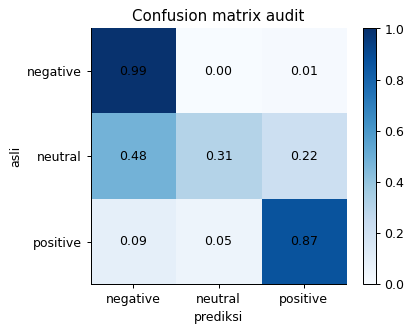

In [14]:
plot_confusion(audit["label"], final_pred, CLASSES, "Confusion matrix audit")

**Demo MBG.** Tidak ada label, jadi hasilnya perlu dibaca. Sebaran aspek menunjukkan isu yang paling sering dibahas.

In [15]:
if USE_PRETRAINED:
    with stage("llm_mbg"):
        raw_mbg = llm_generate(llm_tokenizer, llm_model, mbg.tolist())
resolved_mbg, mbg_from_llm = resolve(raw_mbg, mbg.tolist())
mbg_table = pd.DataFrame(resolved_mbg).assign(komentar=mbg.str[:90])
print("aspek:", mbg_table["aspek"].value_counts(normalize=True).round(3).to_dict())
print("sentimen:", mbg_table["sentimen"].value_counts(normalize=True).round(3).to_dict())
mbg_table.to_csv(RESULT_DIR / "ekstraksi_mbg.csv", index=False)
mbg_table.head(6)

[waktu] llm_mbg: 97 detik


aspek: {'anggaran': 0.597, 'korupsi': 0.283, 'dapur': 0.071, 'lainnya': 0.041, 'keracunan': 0.008}
sentimen: {'negatif': 0.82, 'positif': 0.157, 'netral': 0.023}


,sentimen,aspek,komentar
0,positif,anggaran,"aku setuju , tengkulak mbh, perlu diperhatikan dan di awasi,,,,,"
1,negatif,anggaran,mudah mudahan di dengar pemerintah dan dijalankan
2,negatif,korupsi,presiden dn menteri keuangan pihak yg paling bertanggung jwb atas kerugian uang negara...
3,negatif,anggaran,"kebijakan jelek, tata kelola jelek, cuman ya gimana lagi terlanjur nyemplung"
4,negatif,anggaran,"manfaat ke petani langsung belum ada ,yang ada baru ke tengkulak"
5,negatif,anggaran,sekolah smpai ke perguruan tinggi aja bisa kog makan bergizi aja ga bisa..yg tolol siapa


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [16]:
pd.DataFrame({"id": audit.index, "label": final_pred}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
run_summary(
    "llm_ekstraksi",
    len(audit) + len(mbg),
    {
        "lolos_skema_tanpa_ulang": round(first_pass_ok, 3),
        **{r["metode"]: r["macro_f1_audit"] for r in results},
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=llm_ekstraksi mode=penuh n_rows=1500 total_detik=874 gpu=True
{
 "lolos_skema_tanpa_ulang": 0.9,
 "kata_kunci": 0.6101,
 "llm_plus_pengaman": 0.7264
}


**Poin untuk presentasi**

- LLM + pengaman macro-F1 0,7264, sedangkan kata kunci 0,6101.
- Mengulang jawaban hanya menaikkan lolos skema dari 90,0% ke 90,6%. Sisanya tetap perlu nilai cadangan.
- Aspek pada data MBG tidak diaudit, dan contoh menunjukkan banyak salah, misalnya komentar harapan dianggap negatif. Jangan jadikan ini angka resmi.
- 1.000 komentar selesai dalam 97 detik. Cocok untuk rangkuman cepat, bukan pengganti model utama.